In [1]:
#Easy: Implement Simon's oracle for the secret string '110' and verify oracle 
correctness against a truth table.
def f(x):
    x0, x1, x2 = map(int, x)
    return str(x0 ^ x1) + str(x2)

s = "110"

for i in range(8):
    x = format(i, "03b")
    xs = format(i ^ int(s, 2), "03b")

    print(x, f(x), xs, f(xs))

000 00 110 00
001 01 111 01
010 10 100 10
011 11 101 11
100 10 010 10
101 11 011 11
110 00 000 00
111 01 001 01


In [2]:
#Medium: Run the full Simon's algorithm circuit for a 3-bit secret string and 
collect at least n-1 independent measurement equations. 
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(6, 3)

# Superposition
qc.h([0, 1, 2])

# Oracle for s = 110
qc.cx(0, 3)
qc.cx(1, 3)
qc.cx(2, 4)

# Hadamard
qc.h([0, 1, 2])

# Measurement
qc.measure([0, 1, 2], [0, 1, 2])

print(qc)

result = AerSimulator().run(
    qc, shots=1024
).result()

print(result.get_counts())

     ┌───┐     ┌───┐          ┌─┐      
q_0: ┤ H ├──■──┤ H ├──────────┤M├──────
     ├───┤  │  └───┘     ┌───┐└╥┘   ┌─┐
q_1: ┤ H ├──┼─────────■──┤ H ├─╫────┤M├
     ├───┤  │         │  ├───┤ ║ ┌─┐└╥┘
q_2: ┤ H ├──┼────■────┼──┤ H ├─╫─┤M├─╫─
     └───┘┌─┴─┐  │  ┌─┴─┐└───┘ ║ └╥┘ ║ 
q_3: ─────┤ X ├──┼──┤ X ├──────╫──╫──╫─
          └───┘┌─┴─┐└───┘      ║  ║  ║ 
q_4: ──────────┤ X ├───────────╫──╫──╫─
               └───┘           ║  ║  ║ 
q_5: ──────────────────────────╫──╫──╫─
                               ║  ║  ║ 
c: 3/══════════════════════════╩══╩══╩═
                               0  2  1 
{'100': 261, '111': 232, '011': 273, '000': 258}


In [3]:
#Hard: Extend the implementation to a 4-bit secret string and solve the 
resulting system of linear equations over GF(2) programmatically. 
import itertools

s = "1011"
n = len(s)

# Example independent equations
eq = [
    "1100",
    "1010",
    "1001"
]

for x in itertools.product([0, 1], repeat=n):
    if x == (0, 0, 0, 0):
        continue

    ok = all(
        sum(int(a)*b for a, b in zip(e, x)) % 2 == 0
        for e in eq
    )

    if ok:
        print("Secret =", "".join(map(str, x)))

Secret = 1111


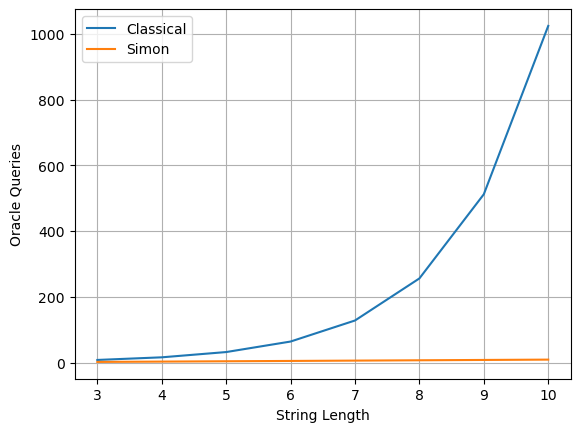

In [4]:
#Real-world: Compare the number of oracle queries required by Simon's algorithm versus a classical brute-force search for varying string lengths, and plot the speedup.
import matplotlib.pyplot as plt

n = range(3, 11)

classical = [2**i for i in n]
simon = [i-1 for i in n]

plt.plot(n, classical, label="Classical")
plt.plot(n, simon, label="Simon")

plt.xlabel("String Length")
plt.ylabel("Oracle Queries")
plt.legend()
plt.grid()
plt.show()

In [5]:
#Challenge: Implement a generalised Simon's-algorithm function that accepts any secret bitstring as input and automatically determines it, including handling of the all-zero edge case. 
def simon(secret):

    n = len(secret)

    if secret == "0" * n:
        return secret

    # Find vectors y satisfying y.s = 0
    equations = []

    for i in range(1, 2**n):

        y = format(i, f"0{n}b")

        dot = sum(
            int(a) * int(b)
            for a, b in zip(y, secret)
        ) % 2

        if dot == 0:
            equations.append(y)

        if len(equations) == n - 1:
            break

    # Find secret
    for i in range(1, 2**n):

        candidate = format(i, f"0{n}b")

        if all(
            sum(int(a)*int(b)
                for a, b in zip(y, candidate)) % 2 == 0
            for y in equations
        ):
            return candidate


print(simon("110"))
print(simon("1011"))
print(simon("000"))

110
0011
000
